In [9]:
import pandas as pd
import numpy as np
import statsmodels.api as sm

# 1. Filter / Select relevant features
features = [
    'subway', 'distance_to_center_km', 'ladderRatio', 
    'amenity_score', 'building_age', 'square',
    'renovationCondition', 'high_floor_with_elevator'
]

df = pd.read_csv("/Users/lzh/Downloads/NUS Y4S1 Downloads/BT2102/Assignment 3/data/processed/BeijingHousingPrices_featured.csv")

# Create district dummy variables
df_encoded = pd.get_dummies(df, columns=['district_name'], drop_first=True)
district_cols = [c for c in df_encoded.columns if c.startswith('district_name_')]

X_cols = features + district_cols
X = sm.add_constant(df_encoded[X_cols].dropna())
y = df_encoded.loc[X.index, 'log_price_per_sqm']

# 2. Fit OLS Regression Model
model = sm.OLS(y, X).fit()
print(model.summary())

/var/folders/hd/rg1pd_9n27l1j1s6_8hcl6rm0000gn/T/ipykernel_5742/2305087802.py:12: DtypeWarning: Columns (1: id) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/Users/lzh/Downloads/NUS Y4S1 Downloads/BT2102/Assignment 3/data/processed/BeijingHousingPrices_featured.csv")


                            OLS Regression Results                            
Dep. Variable:      log_price_per_sqm   R-squared:                       0.479
Model:                            OLS   Adj. R-squared:                  0.479
Method:                 Least Squares   F-statistic:                 1.368e+04
Date:                Tue, 27 Oct 2026   Prob (F-statistic):               0.00
Time:                        22:10:22   Log-Likelihood:            -1.1619e+05
No. Observations:              297380   AIC:                         2.324e+05
Df Residuals:                  297359   BIC:                         2.326e+05
Df Model:                          20                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                 

In [11]:
# Calculate predictions and residuals
df_encoded['predicted_log_price'] = model.predict(X)
df_encoded['residual'] = df_encoded['log_price_per_sqm'] - df_encoded['predicted_log_price']

# Group by District / Strategy to compare expected return vs risk
strategy_summary = df_encoded.groupby(df['district_name']).agg(
    mean_predicted_price=('predicted_log_price', 'mean'),
    expected_return_premium=('price_diff_pct', 'mean'),
    risk_volatility=('residual', 'std'),
    sample_size=('log_price_per_sqm', 'count')
).reset_index()

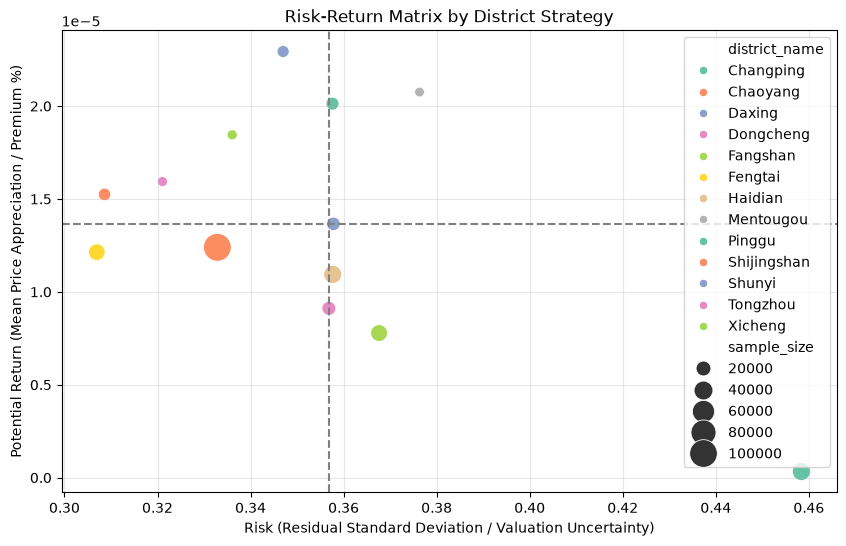

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=strategy_summary, 
    x='risk_volatility', 
    y='expected_return_premium', 
    size='sample_size', 
    hue='district_name',
    sizes=(50, 400),
    palette='Set2'
)

# Quadrant reference lines (Median split)
plt.axvline(strategy_summary['risk_volatility'].median(), color='gray', linestyle='--')
plt.axhline(strategy_summary['expected_return_premium'].median(), color='gray', linestyle='--')

plt.title('Risk-Return Matrix by District Strategy')
plt.xlabel('Risk (Residual Standard Deviation / Valuation Uncertainty)')
plt.ylabel('Potential Return (Mean Price Appreciation / Premium %)')
plt.grid(True, alpha=0.3)
plt.show()

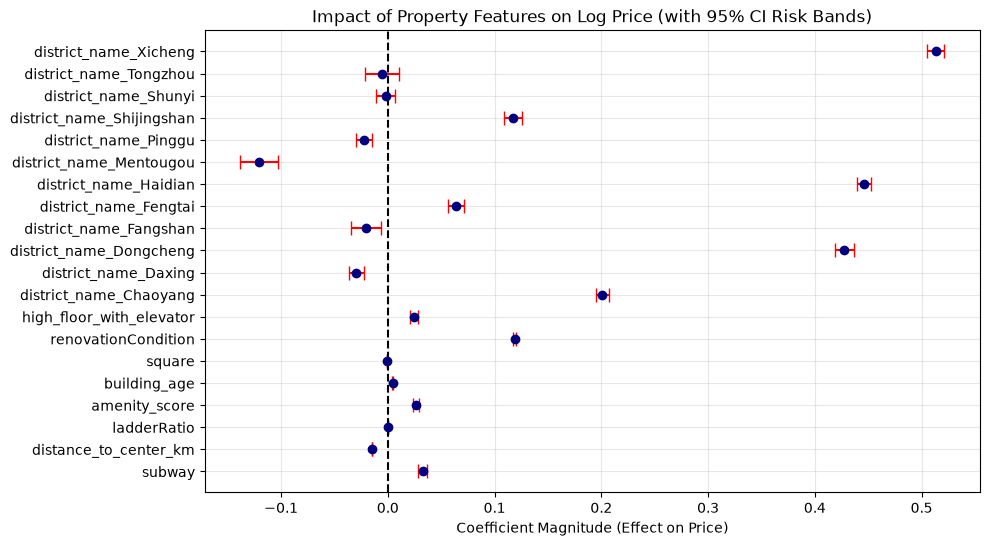

In [13]:
# Extract coefficients and confidence intervals
coef_df = model.conf_int().reset_index()
coef_df.columns = ['Feature', 'lower', 'upper']
coef_df['coef'] = model.params.values
coef_df = coef_df[coef_df['Feature'] != 'const']

plt.figure(figsize=(10, 6))
plt.errorbar(
    y=coef_df['Feature'], 
    x=coef_df['coef'], 
    xerr=[coef_df['coef'] - coef_df['lower'], coef_df['upper'] - coef_df['coef']], 
    fmt='o', color='navy', ecolor='red', capsize=5
)
plt.axvline(0, color='black', linestyle='--')
plt.title('Impact of Property Features on Log Price (with 95% CI Risk Bands)')
plt.xlabel('Coefficient Magnitude (Effect on Price)')
plt.grid(True, alpha=0.3)
plt.show()